# Dynamic Minimum-VaR Portfolio

This notebook repeats the Stage 3 construction (`portoflio.ipynb`) but lets the portfolio **reallocate** as time passes. $10,000 is invested at the start of 2018 and the target expected year-on-year return is the same. At every rebalance date, **the whole accumulated value** is re-split across the NIFTY 50, S&P 500 and Euro Stoxx 50 so that the forecast VaR over the coming period is as low as possible while still meeting the target.

**What changes at each rebalance date $d$.** Only data up to and including the close on day $d$ is used:

| Input | Static portfolio (Stage 3) | Dynamic portfolio (this notebook) |
|:--|:--|:--|
| GARCH parameters | fitted once on data to 2017 | **re-estimated** on all data up to $d$ (expanding window) |
| Volatility forecast | average over all of 2018–2025, made in Dec 2017 | average over the **next holding period only**, made at $d$ |
| Correlations | training-period residuals | **rolling** window of recent standardised residuals |
| Expected returns | training-period mean | mean of all returns up to $d$ (expanding) |
| Weights | set once, then drift | **reset** to the new optimum, using the accumulated value |

**"Minimise risk when possible."** At each date the optimiser finds the lowest-VaR mix whose expected return meets the target. If no long-only mix can reach the target (the target is above every index's expected return at that time), it falls back to the rule set by `IF_INFEASIBLE` and records the date.

The dynamic portfolio is compared with the static Stage 3 portfolio and with holding each index alone.

**Assumptions.** These are the same as in Stage 3: local-currency (hedged) price returns, no dividends, and fractional holdings. Transaction costs are a parameter, set to zero by default.

In [1]:
# ===================== USER PARAMETERS =====================
INITIAL_INVESTMENT   = 10_000     # dollars
TARGET_RETURN        = 0.09       # target expected year-on-year return (same as Stage 3)
VAR_LEVEL            = 0.99       # VaR confidence level used in the optimisation
ALLOW_SHORT          = False      # False: weights between 0 and 1

REBALANCE_FREQ       = "M"        # "W" weekly, "M" monthly, "Q" quarterly
REFIT_GARCH          = True       # re-estimate GARCH parameters at every rebalance
CORR_WINDOW          = 500        # trading days of residuals for the correlation matrix (None = expanding)
RETURN_WINDOW        = None       # trading days for expected returns (None = expanding since 2007)
IF_INFEASIBLE        = "max_return"   # target unreachable: "max_return" (closest to target) or "min_var"
TRANSACTION_COST_BPS = 0.0        # cost per unit of turnover, in basis points (10 = 0.10%)
# ===========================================================

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from arch import arch_model
from scipy import stats
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.4f}".format)

SPLIT = "2018-01-01"
DATA = Path("data")
INDICES = {"NIFTY 50": "nifty50", "S&P 500": "sp500", "Euro Stoxx 50": "eurostoxx50"}
NAMES = list(INDICES)
COLORS = {"Dynamic portfolio": "crimson", "Static portfolio": "k",
          "NIFTY 50": "C1", "S&P 500": "C0", "Euro Stoxx 50": "C2"}

## 1. Data

The data and calendar are the same as in Stage 3. Prices are aligned on the union of the three markets' trading days, and a closed market's price is carried forward, so its return is zero that day. GARCH models are fitted on each index's own trading days.

In [3]:
def load_prices(slug):
    p = pd.read_csv(DATA / f"{slug}_daily.csv", index_col="Date", parse_dates=True)["Close"]
    return p.dropna()[lambda s: ~s.index.duplicated()]

own_prices = {n: load_prices(s) for n, s in INDICES.items()}
own_ret = {n: (100 * np.log(p).diff()).dropna() for n, p in own_prices.items()}
P = pd.DataFrame(own_prices).ffill().dropna()[NAMES]
simple_ret = P.pct_change().dropna()

last_train = P.index[P.index < SPLIT][-1]
test_idx = P.index[P.index >= SPLIT]
full_models = {n: arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t")
               for n, r in own_ret.items()}
print(f"Common calendar {P.index[0].date()} -> {P.index[-1].date()};  "
      f"test {test_idx[0].date()} -> {test_idx[-1].date()} ({len(test_idx)} days)")

Common calendar 2007-09-17 -> 2025-12-31;  test 2018-01-02 -> 2025-12-31 (2073 days)


## 2. Building blocks

### 2a. Model at a rebalance date

`fit_at(name, d)` estimates GJR-GARCH(1,1,1)-t on the index's returns **up to and including day $d$**. Its parameters are then *fixed* on the full return series, which gives:

* in-sample standardised residuals up to $d$, used for correlations,
* a multi-step variance forecast from $d$, used for planning, and
* one-step-ahead variance forecasts for each day of the holding period, using the actual returns as they arrive but no re-estimation, used for daily VaR monitoring.

Results are cached so that each (index, date) pair is fitted only once.

In [4]:
_cache = {}

def fit_at(name, d):
    key = (name, d)
    if key not in _cache:
        r = own_ret[name][own_ret[name].index <= d]
        res = arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t").fit(disp="off")
        fixed = full_models[name].fix(res.params.values)
        _cache[key] = {"params": res.params, "fixed": fixed,
                       "z": (fixed.resid / fixed.conditional_volatility)[lambda s: s.index <= d]}
    return _cache[key]

def own_last(name, d):
    idx = own_ret[name].index
    return idx[idx <= d][-1]

### 2b. Planning inputs at a rebalance date

For a holding period from $d$ to the next rebalance date:

* **Planning volatility** $\sigma_i^{plan} = \sqrt{\tfrac1H\sum_{h=1}^{H}\hat\sigma^2_{i,d+h|d}}$, the average forecast variance over the $H$ trading days of that index in the period.
* **Correlation** $R$ of standardised residuals over the last `CORR_WINDOW` common trading days up to $d$.
* **Expected return** $\mu_i$: the mean daily simple return up to $d$, × 252 for the annual figure used in the constraint.
* **Tail parameter** $\nu_i$ from the current fit.

In [5]:
def planning_inputs(d, horizon_days, param_date, corr_window, return_window):
    fits = {n: fit_at(n, param_date) for n in NAMES}
    sig = []
    for n in NAMES:
        H = max(1, int(((own_ret[n].index > d) & (own_ret[n].index <= horizon_days[-1])).sum()))
        fc = fits[n]["fixed"].forecast(horizon=H, start=own_last(n, d), reindex=False)
        sig.append(np.sqrt(fc.variance.iloc[0].values.mean()))
    z = pd.DataFrame({n: fits[n]["z"] for n in NAMES}).dropna()
    z = z[(z.index >= P.index[0]) & (z.index <= d)]
    if corr_window:
        z = z.iloc[-corr_window:]
    sr = simple_ret[simple_ret.index <= d]
    if return_window:
        sr = sr.iloc[-return_window:]
    return {
        "mu_d": 100 * sr.mean()[NAMES].values,          # % daily
        "mu_a": 252 * sr.mean()[NAMES].values,          # fraction, annual
        "sig": np.array(sig),                           # % daily
        "R": z.corr().loc[NAMES, NAMES].values,
        "NU": np.array([fits[n]["params"]["nu"] for n in NAMES]),
        "fits": fits,
    }

### 2c. Optimiser

This is the same objective as Stage 3:

$$\min_w\; -\left(w^\top\mu - q_{\nu(w)}\sqrt{w^\top D R D\,w}\right)\quad\text{s.t.}\quad w^\top\mu^{annual}\ge\text{target},\;\; \textstyle\sum w_i=1,\;\; 0\le w_i\le1$$

In [6]:
def t_quantile(c, nu):
    return stats.t.ppf(c, nu) * np.sqrt((nu - 2) / nu)        # unit-variance Student-t

def port_var(w, inp, c=VAR_LEVEL):
    cov = np.outer(inp["sig"], inp["sig"]) * inp["R"]
    return -(w @ inp["mu_d"] - t_quantile(c, float(w @ inp["NU"])) * np.sqrt(max(w @ cov @ w, 0)))

def optimise(inp, target, c=VAR_LEVEL):
    # returns (weights, feasible flag)
    n = len(NAMES)
    if not ALLOW_SHORT and target > inp["mu_a"].max() + 1e-9:
        if IF_INFEASIBLE == "max_return":
            return np.eye(n)[np.argmax(inp["mu_a"])], False
        target = -np.inf
        feasible = False
    else:
        feasible = True
    bounds = None if ALLOW_SHORT else [(0, 1)] * n
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
    if np.isfinite(target):
        cons.append({"type": "ineq", "fun": lambda w: w @ inp["mu_a"] - target})
    best = None
    for w0 in [np.full(n, 1 / n), np.eye(n)[np.argmax(inp["mu_a"])], *np.eye(n)]:
        res = minimize(port_var, w0, args=(inp, c), bounds=bounds, constraints=cons,
                       method="SLSQP", options={"ftol": 1e-12, "maxiter": 500})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    w = best.x if best is not None else np.eye(n)[np.argmax(inp["mu_a"])]
    if not ALLOW_SHORT:
        w = np.clip(w, 0, None)
    return w / w.sum(), feasible

### 2d. Strategy simulator

A single engine runs every strategy:

1. **On each rebalance date $d$** (the last trading day of each week, month or quarter):
   * compute the current value $V_d$ of the holdings,
   * re-fit the models (if `REFIT_GARCH`), build the planning inputs and solve for new weights $w_d$,
   * pay transaction costs of $\text{bps} \times \sum_i |w_{d,i} - w^{drift}_{d,i}| \times V_d$, and
   * buy units $V_d\,w_{d,i} / P_{i,d}$ of each index.
2. **On every day in between**, hold the units (the weights drift) and compute the one-day VaR from the one-step GARCH forecasts, the current drifted weights and the correlation matrix from the last rebalance.

With `freq=None` and fixed weights, the same engine reproduces the static Stage 3 portfolio and the single-index portfolios.

In [7]:
def rebalance_dates(freq):
    if freq is None:
        return [last_train]
    idx = P.index[P.index >= last_train]
    ends = idx.to_series().groupby(idx.to_period(freq)).last()
    ends = [d for d in ends if last_train < d < test_idx[-1]]
    return [last_train] + ends

def run_strategy(freq=REBALANCE_FREQ, refit=REFIT_GARCH, target=TARGET_RETURN,
                 corr_window=CORR_WINDOW, return_window=RETURN_WINDOW,
                 tc_bps=TRANSACTION_COST_BPS, fixed_weights=None):
    dates = rebalance_dates(freq)
    units, rows, log = None, [], []
    for k, d in enumerate(dates):
        end = dates[k + 1] if k + 1 < len(dates) else test_idx[-1]
        days = P.index[(P.index > d) & (P.index <= end)]
        if len(days) == 0:
            continue
        inp = planning_inputs(d, days, d if refit else last_train, corr_window, return_window)

        if fixed_weights is not None:
            w, feasible = np.asarray(fixed_weights, float), True
        else:
            w, feasible = optimise(inp, target)

        px = P.loc[d].values
        if units is None:
            V, w_drift, cost = INITIAL_INVESTMENT, None, 0.0
        else:
            V = float(units @ px)
            w_drift = units * px / V
            cost = tc_bps / 1e4 * np.abs(w - w_drift).sum() * V
            V -= cost
        turnover = 0.0 if w_drift is None else 0.5 * np.abs(w - w_drift).sum()
        units = V * w / px
        log.append({"date": d, **dict(zip(NAMES, w)), "feasible": feasible, "turnover": turnover,
                    "cost": cost, "value": V, "exp_return": w @ inp["mu_a"],
                    "planned_VaR": port_var(w, inp), **{f"mu {n}": m for n, m in zip(NAMES, inp["mu_a"])}})

        # one-step-ahead sigma / mu on each index's own days, mapped to the common calendar
        sig_t, mu_t = {}, {}
        for n in NAMES:
            fc = inp["fits"][n]["fixed"].forecast(horizon=1, start=own_last(n, d), reindex=False)
            s = np.sqrt(fc.variance["h.1"]).shift(1)
            m = fc.mean["h.1"].shift(1)
            is_open = days.isin(own_ret[n].index)
            sig_t[n] = np.where(is_open, s.reindex(days).ffill().values, 0.0)
            mu_t[n] = np.where(is_open, m.reindex(days).ffill().values, 0.0)
        sig_t, mu_t = pd.DataFrame(sig_t, index=days), pd.DataFrame(mu_t, index=days)

        hold = P.loc[days].values * units
        prev_hold = np.vstack([units * px, hold[:-1]])
        prev_val = prev_hold.sum(axis=1)
        w_t = prev_hold / prev_val[:, None]
        X = w_t * sig_t.values
        pvar = np.einsum("ni,ij,nj->n", X, inp["R"], X)
        nu_t = w_t @ inp["NU"]
        var_pct = -((w_t * mu_t.values).sum(axis=1) - t_quantile(VAR_LEVEL, nu_t) * np.sqrt(pvar))
        val = hold.sum(axis=1)
        rows.append(pd.DataFrame({
            "value": val, "prev_value": prev_val,
            "ret_pct": 100 * (val / prev_val - 1), "log_ret_pct": 100 * np.log(val / prev_val),
            "VaR_pct": var_pct, "port_sigma": np.sqrt(pvar),
            **{f"w {n}": w_t[:, i] for i, n in enumerate(NAMES)},
        }, index=days))
        # costs reduce value at the rebalance itself; record against the first day of the period
        rows[-1].iloc[0, rows[-1].columns.get_loc("prev_value")] += cost
        rows[-1].iloc[0, rows[-1].columns.get_loc("ret_pct")] = 100 * (val[0] / (prev_val[0] + cost) - 1)
        rows[-1].iloc[0, rows[-1].columns.get_loc("log_ret_pct")] = 100 * np.log(val[0] / (prev_val[0] + cost))

    out = pd.concat(rows)
    out["VaR_usd"] = out["VaR_pct"] / 100 * out["prev_value"]
    out["loss_usd"] = out["prev_value"] - out["value"]
    return out, pd.DataFrame(log).set_index("date")

## 3. Run the strategies

* **Dynamic portfolio:** rebalanced every `REBALANCE_FREQ` with the settings above.
* **Static portfolio:** the Stage 3 construction, using training-period inputs, one allocation and then buy and hold. It is re-run here with the same engine as a check.
* **Single indices:** 100% in each index, buy and hold.

In [8]:
dyn, dyn_log = run_strategy()

_static_inp = planning_inputs(last_train, test_idx, last_train, None, None)
static_w, _ = optimise(_static_inp, TARGET_RETURN)
static, static_log = run_strategy(freq=None, refit=False, corr_window=None, fixed_weights=static_w)

results = {"Dynamic portfolio": dyn, "Static portfolio": static}
for i, n in enumerate(NAMES):
    results[n], _ = run_strategy(freq=None, refit=False, corr_window=None, fixed_weights=np.eye(3)[i])

print(f"Rebalances: {len(dyn_log)}   "
      f"target infeasible on {(~dyn_log['feasible']).sum()} of them")
print("Static weights (check against Stage 3): "
      + ", ".join(f"{n} {w:.1%}" for n, w in zip(NAMES, static_w))
      + f"  -> final value ${static['value'].iloc[-1]:,.0f}")

Rebalances: 96   target infeasible on 4 of them
Static weights (check against Stage 3): NIFTY 50 45.2%, S&P 500 54.8%, Euro Stoxx 50 0.0%  -> final value $25,246


## 4. How the allocation moved

Top: the dynamic weights chosen at each rebalance date. Middle: the expected annual return of each index as estimated at each date, against the target. Bottom: the forecast VaR at each rebalance, planned for the coming period, for the dynamic portfolio and for each index alone.

,NIFTY 50,S&P 500,Euro Stoxx 50
mean,54.0%,40.4%,5.7%
min,12.5%,0.0%,0.0%
max,100.0%,83.4%,25.1%
share of rebalances held (>1%),100.0%,95.8%,51.0%


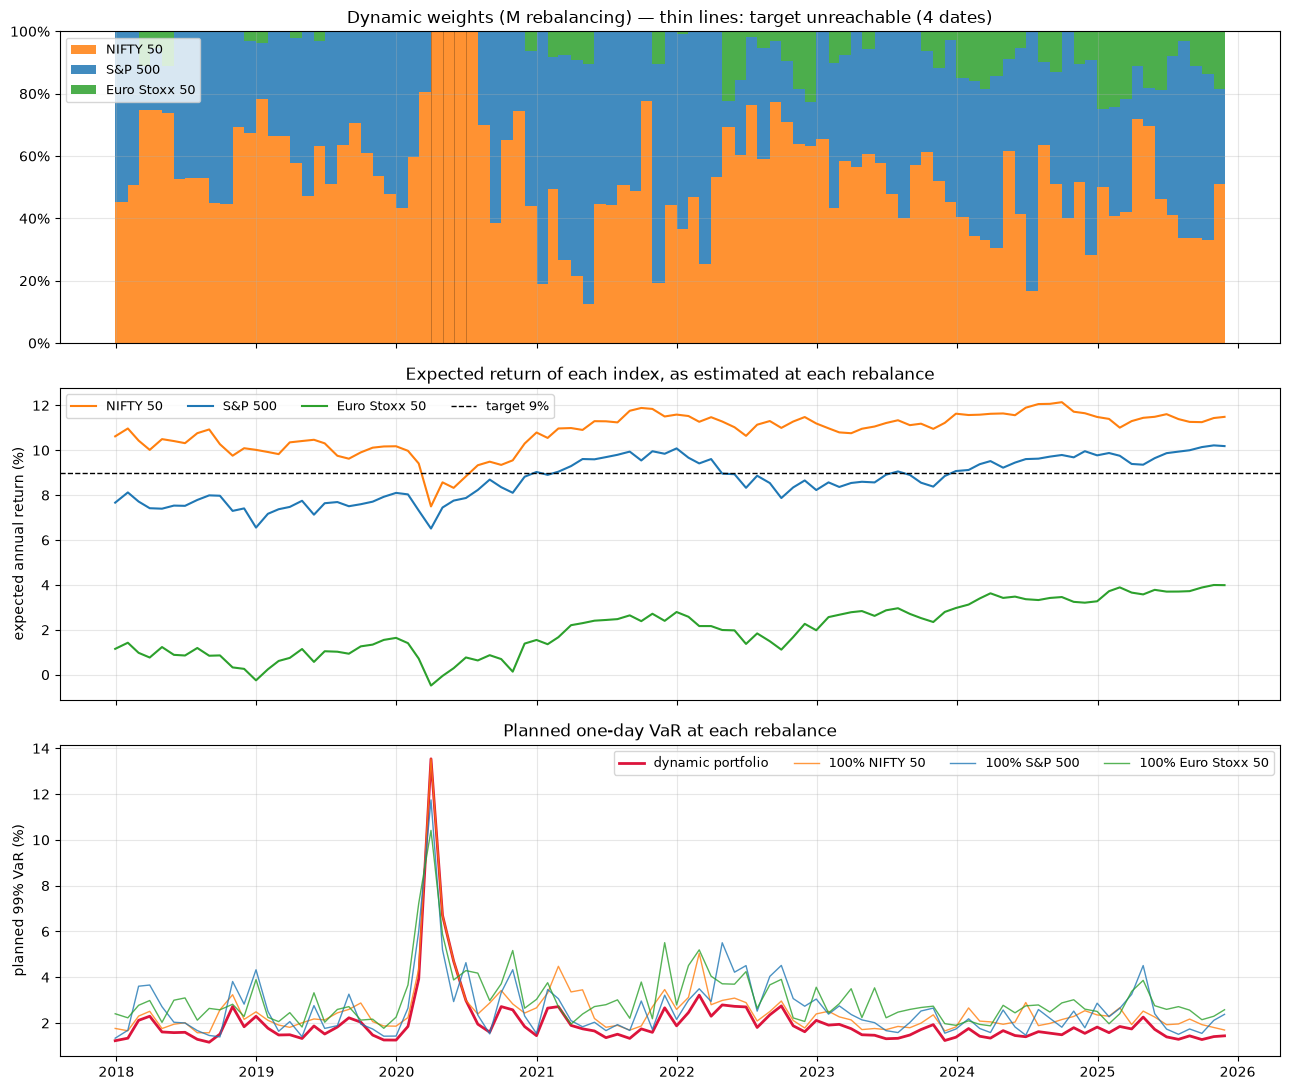

In [9]:
fig, ax = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
ax[0].stackplot(dyn_log.index, *[dyn_log[n] for n in NAMES], labels=NAMES,
                colors=[COLORS[n] for n in NAMES], alpha=0.85, step="post")
infeas = dyn_log.index[~dyn_log["feasible"]]
for d in infeas:
    ax[0].axvline(d, color="k", lw=0.4, alpha=0.4)
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[0].set_ylim(0, 1)
ax[0].set_title(f"Dynamic weights ({REBALANCE_FREQ} rebalancing)"
                + (f" — thin lines: target unreachable ({len(infeas)} dates)" if len(infeas) else ""))
ax[0].legend(loc="upper left", fontsize=9)

for n in NAMES:
    ax[1].plot(dyn_log.index, 100 * dyn_log[f"mu {n}"], color=COLORS[n], label=n)
ax[1].axhline(100 * TARGET_RETURN, color="k", ls="--", lw=1, label=f"target {TARGET_RETURN:.0%}")
ax[1].set_ylabel("expected annual return (%)"); ax[1].legend(fontsize=9, ncol=4)
ax[1].set_title("Expected return of each index, as estimated at each rebalance")

ax[2].plot(dyn_log.index, dyn_log["planned_VaR"], color=COLORS["Dynamic portfolio"], lw=2, label="dynamic portfolio")
single_var = {}
for i, n in enumerate(NAMES):
    single_var[n] = [port_var(np.eye(3)[i], planning_inputs(d, P.index[(P.index > d)][:21], d, CORR_WINDOW, RETURN_WINDOW))
                     for d in dyn_log.index]
    ax[2].plot(dyn_log.index, single_var[n], color=COLORS[n], lw=1, alpha=0.8, label=f"100% {n}")
ax[2].set_ylabel(f"planned {VAR_LEVEL:.0%} VaR (%)"); ax[2].legend(fontsize=9, ncol=4)
ax[2].set_title("Planned one-day VaR at each rebalance")
plt.tight_layout()

summary_w = dyn_log[NAMES].describe().loc[["mean", "min", "max"]]
summary_w.loc["share of rebalances held (>1%)"] = (dyn_log[NAMES] > 0.01).mean()
summary_w.style.format("{:.1%}")

## 5. Growth of $10,000 and daily VaR

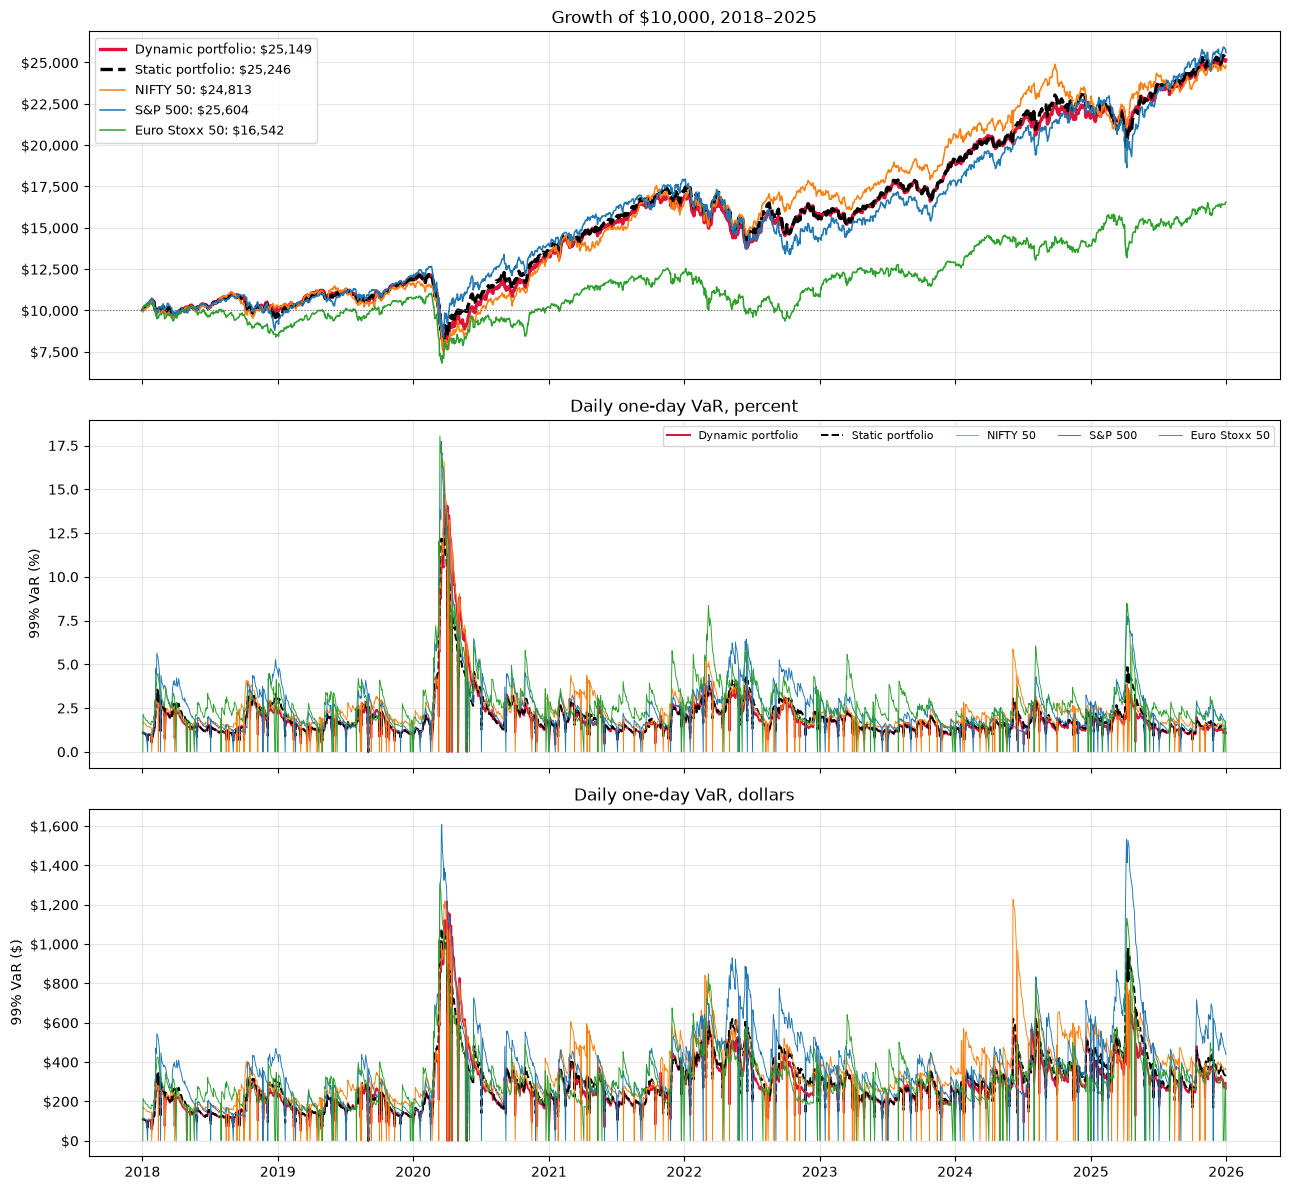

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for label, df in results.items():
    lw = 2.4 if "portfolio" in label else 1.1
    ls = "-" if label != "Static portfolio" else "--"
    ax[0].plot(df.index, df["value"], color=COLORS[label], lw=lw, ls=ls,
               label=f"{label}: ${df['value'].iloc[-1]:,.0f}")
    ax[1].plot(df.index, df["VaR_pct"], color=COLORS[label], lw=lw * 0.6, ls=ls, label=label)
    ax[2].plot(df.index, df["VaR_usd"], color=COLORS[label], lw=lw * 0.6, ls=ls, label=label)
ax[0].axhline(INITIAL_INVESTMENT, color="0.4", lw=0.8, ls=":")
ax[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax[0].set_title(f"Growth of ${INITIAL_INVESTMENT:,}, 2018–2025"); ax[0].legend(loc="upper left", fontsize=9)
ax[1].set_ylabel(f"{VAR_LEVEL:.0%} VaR (%)"); ax[1].set_title("Daily one-day VaR, percent")
ax[2].set_ylabel(f"{VAR_LEVEL:.0%} VaR ($)"); ax[2].set_title("Daily one-day VaR, dollars")
ax[2].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax[1].legend(fontsize=8, ncol=5)
plt.tight_layout()

## 6. Risk and return comparison

The metrics are the same as in Stage 3, plus three rows for the dynamic strategy: the number of rebalances, the average one-way turnover per rebalance and the total transaction costs. Green marks the best strategy on each row and red the worst.

In [11]:
def kupiec_p(hits, p):
    n, x = len(hits), int(hits.sum())
    if x == 0:
        lr = -2 * n * np.log(1 - p)
    else:
        pi = x / n
        lr = -2 * ((n - x) * np.log(1 - p) + x * np.log(p) - (n - x) * np.log(1 - pi) - x * np.log(pi))
    return 1 - stats.chi2.cdf(lr, 1)

def christoffersen_p(hits):
    h = hits.astype(int).values
    a, b = h[:-1], h[1:]
    n00, n01 = ((a == 0) & (b == 0)).sum(), ((a == 0) & (b == 1)).sum()
    n10, n11 = ((a == 1) & (b == 0)).sum(), ((a == 1) & (b == 1)).sum()
    ll = lambda k, q: k * np.log(q) if k else 0.0
    pi0 = n01 / max(n00 + n01, 1); pi1 = n11 / max(n10 + n11, 1); pi = (n01 + n11) / max(len(a), 1)
    lr = -2 * ((ll(n00 + n10, 1 - pi) + ll(n01 + n11, pi)) -
               (ll(n00, 1 - pi0) + ll(n01, pi0) + ll(n10, 1 - pi1) + ll(n11, pi1)))
    return 1 - stats.chi2.cdf(lr, 1)

def metrics(df, log=None):
    v = df["value"]
    years = len(df) / 252
    cagr = (v.iloc[-1] / INITIAL_INVESTMENT) ** (1 / years) - 1
    r = df["ret_pct"] / 100
    ye = v.groupby(v.index.year).last()
    yearly = ye / np.r_[INITIAL_INVESTMENT, ye.values[:-1]] - 1
    hits = df["log_ret_pct"] < -df["VaR_pct"]
    m = {
        "Final value ($)": v.iloc[-1],
        "Total return": v.iloc[-1] / INITIAL_INVESTMENT - 1,
        "Annualised return (CAGR)": cagr,
        "Best year": yearly.max(),
        "Worst year": yearly.min(),
        "Avg forecast 99% VaR (%)": df["VaR_pct"].mean(),
        "Avg forecast 99% VaR ($)": df["VaR_usd"].mean(),
        "Peak forecast 99% VaR ($)": df["VaR_usd"].max(),
        "Realised 1% daily return (%)": -np.percentile(df["ret_pct"], 1),
        "VaR breaches (days)": int(hits.sum()),
        "VaR breach rate": hits.mean(),
        "Kupiec p": kupiec_p(hits, 1 - VAR_LEVEL),
        "Christoffersen p": christoffersen_p(hits),
        "Annualised volatility": r.std() * np.sqrt(252),
        "Max drawdown": (v / v.cummax() - 1).min(),
        "Worst day ($)": df["loss_usd"].max(),
        "Sharpe ratio (rf = 0)": r.mean() / r.std() * np.sqrt(252),
        "CAGR / avg VaR": 100 * cagr / df["VaR_pct"].mean(),
        "Rebalances": 0 if log is None else max(len(log) - 1, 0),
        "Avg turnover per rebalance": 0.0 if log is None or len(log) < 2 else log["turnover"].iloc[1:].mean(),
        "Transaction costs ($)": 0.0 if log is None else log["cost"].sum(),
    }
    return m

comparison = pd.DataFrame({label: metrics(df, dyn_log if label == "Dynamic portfolio" else None)
                           for label, df in results.items()})

higher_better = {"Final value ($)", "Total return", "Annualised return (CAGR)", "Best year", "Worst year",
                 "Max drawdown", "Sharpe ratio (rf = 0)", "CAGR / avg VaR", "Kupiec p", "Christoffersen p"}
lower_better = {"Avg forecast 99% VaR (%)", "Avg forecast 99% VaR ($)", "Peak forecast 99% VaR ($)",
                "Realised 1% daily return (%)", "Annualised volatility", "Worst day ($)"}

def highlight(row):
    if row.name in higher_better:
        best, worst = row.max(), row.min()
    elif row.name in lower_better:
        best, worst = row.min(), row.max()
    else:
        return [""] * len(row)
    return ["background-color: #d4edda; font-weight: bold" if np.isclose(v, best) else
            "background-color: #f8d7da" if np.isclose(v, worst) else "" for v in row]

FMT = {
    "Final value ($)": "${:,.0f}", "Avg forecast 99% VaR ($)": "${:,.0f}", "Peak forecast 99% VaR ($)": "${:,.0f}",
    "Worst day ($)": "${:,.0f}", "Transaction costs ($)": "${:,.0f}",
    "Total return": "{:.1%}", "Annualised return (CAGR)": "{:.2%}", "Best year": "{:.1%}", "Worst year": "{:.1%}",
    "VaR breach rate": "{:.2%}", "Annualised volatility": "{:.1%}", "Max drawdown": "{:.1%}",
    "Avg turnover per rebalance": "{:.1%}",
    "Avg forecast 99% VaR (%)": "{:.2f}%", "Realised 1% daily return (%)": "{:.2f}%",
    "VaR breaches (days)": "{:.0f}", "Rebalances": "{:.0f}",
    "Kupiec p": "{:.3f}", "Christoffersen p": "{:.3f}", "Sharpe ratio (rf = 0)": "{:.2f}", "CAGR / avg VaR": "{:.2f}",
}

def show(table):
    sty = table.style.apply(highlight, axis=1)
    for row, f in FMT.items():
        if row in table.index:
            sty = sty.format(f, subset=pd.IndexSlice[row, :])
    return sty

show(comparison)

,Dynamic portfolio,Static portfolio,NIFTY 50,S&P 500,Euro Stoxx 50
Final value ($),"$25,149","$25,246","$24,813","$25,604","$16,542"
Total return,151.5%,152.5%,148.1%,156.0%,65.4%
Annualised return (CAGR),11.86%,11.92%,11.68%,12.11%,6.31%
Best year,25.5%,25.7%,24.1%,28.9%,25.5%
Worst year,-6.0%,-9.2%,3.2%,-19.4%,-14.8%
Avg forecast 99% VaR (%),1.92%,2.00%,2.34%,2.58%,2.78%
Avg forecast 99% VaR ($),$280,$298,$352,$383,$311
Peak forecast 99% VaR ($),"$1,216","$1,076","$1,227","$1,606","$1,311"
Realised 1% daily return (%),2.47%,2.40%,2.67%,3.41%,3.64%
VaR breaches (days),36,32,25,33,28


### Risk vs return at a glance

Up and to the left is better.

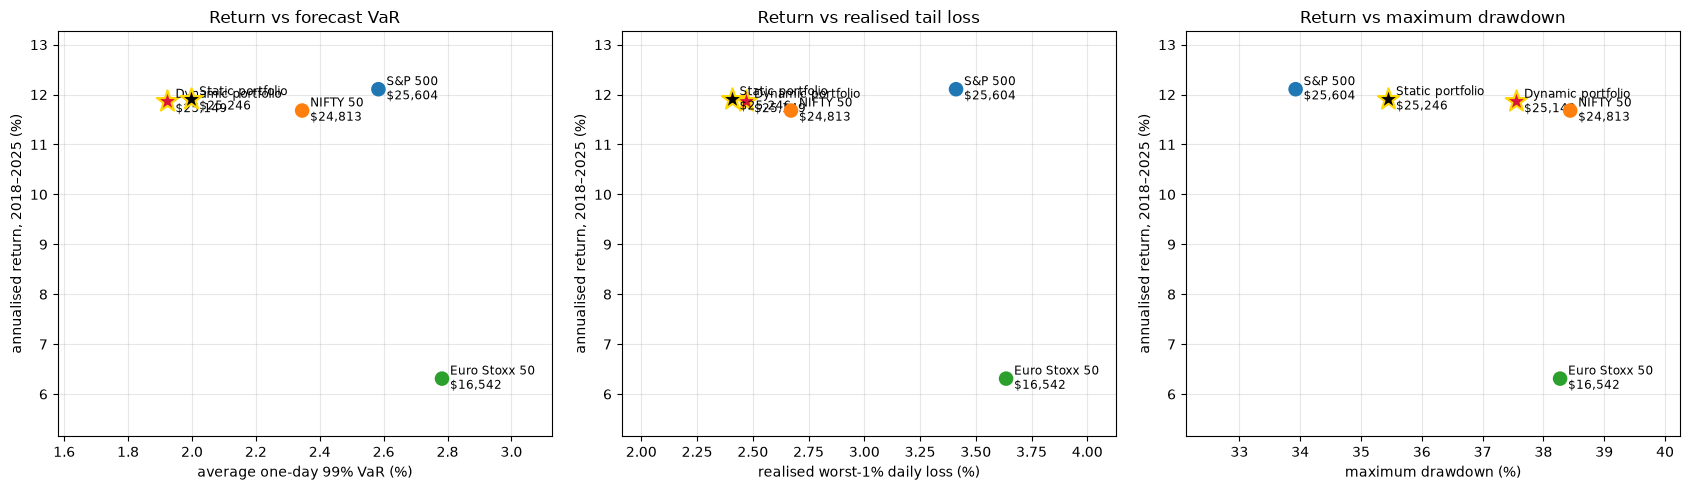

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
xs = [("Avg forecast 99% VaR (%)", "average one-day 99% VaR (%)", 1),
      ("Realised 1% daily return (%)", "realised worst-1% daily loss (%)", 1),
      ("Max drawdown", "maximum drawdown (%)", -100)]
for a, (col, xlabel, scale) in zip(ax, xs):
    for label in results:
        c = comparison[label]
        star = "portfolio" in label
        a.scatter(scale * c[col], 100 * c["Annualised return (CAGR)"], s=260 if star else 110,
                  marker="*" if star else "o", color=COLORS[label], edgecolor="gold" if star else "none",
                  linewidth=1.5, zorder=3)
        a.annotate(f"  {label}\n  ${c['Final value ($)']:,.0f}", (scale * c[col], 100 * c["Annualised return (CAGR)"]),
                   fontsize=8.5, va="center")
    a.set_xlabel(xlabel); a.set_ylabel("annualised return, 2018–2025 (%)"); a.margins(x=0.4, y=0.2)
ax[0].set_title("Return vs forecast VaR"); ax[1].set_title("Return vs realised tail loss")
ax[2].set_title("Return vs maximum drawdown")
plt.tight_layout()

### Year by year

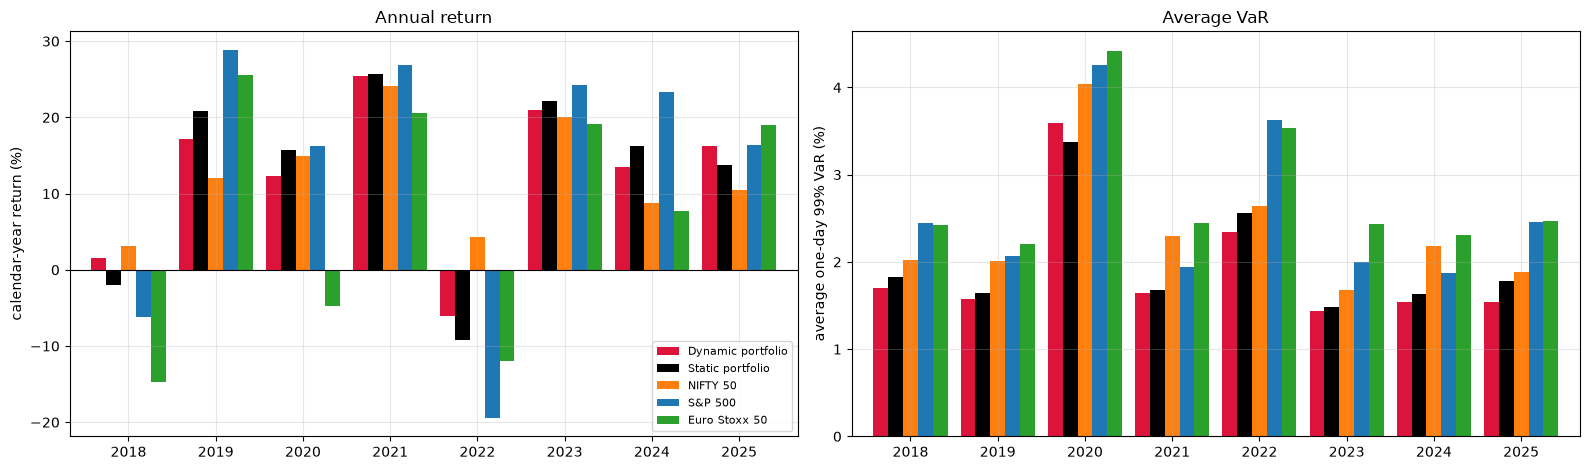

In [13]:
def yearly_stats(df):
    v = df["value"]
    ye = v.groupby(v.index.year).last()
    return pd.DataFrame({"return": ye / np.r_[INITIAL_INVESTMENT, ye.values[:-1]] - 1,
                         "avg VaR (%)": df["VaR_pct"].groupby(df.index.year).mean()})

yearly = pd.concat({label: yearly_stats(df) for label, df in results.items()}, axis=1)
yr_ret = yearly.xs("return", axis=1, level=1)
yr_var = yearly.xs("avg VaR (%)", axis=1, level=1)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
yr_ret.mul(100).plot(kind="bar", ax=ax[0], color=[COLORS[c] for c in yr_ret.columns], width=0.85)
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_ylabel("calendar-year return (%)"); ax[0].set_xlabel("")
ax[0].set_title("Annual return"); ax[0].tick_params(axis="x", rotation=0); ax[0].legend(fontsize=8)
yr_var.plot(kind="bar", ax=ax[1], color=[COLORS[c] for c in yr_var.columns], width=0.85, legend=False)
ax[1].set_ylabel("average one-day 99% VaR (%)"); ax[1].set_xlabel("")
ax[1].set_title("Average VaR"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()

(yearly.style
   .format("{:.1%}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "return"]])
   .format("{:.2f}%", subset=pd.IndexSlice[:, pd.IndexSlice[:, "avg VaR (%)"]])
   .background_gradient(cmap="RdYlGn", vmin=-0.3, vmax=0.3, subset=pd.IndexSlice[:, pd.IndexSlice[:, "return"]])
   .background_gradient(cmap="Reds", subset=pd.IndexSlice[:, pd.IndexSlice[:, "avg VaR (%)"]]))

## 7. VaR calibration

This repeats the Stage 3 check for both portfolios. If the volatility forecast is right, the standardised portfolio return should have a standard deviation near 1. If the tail is right, its 1st percentile should match the t quantile used.

In [14]:
calib = {}
for label in ["Dynamic portfolio", "Static portfolio"]:
    df = results[label]
    w_cols = [f"w {n}" for n in NAMES]
    # expected return term is tiny; standardise by the portfolio sigma used in the VaR
    z = df["log_ret_pct"] / df["port_sigma"]
    nu_avg = float((df[w_cols].values @ _static_inp["NU"]).mean())
    calib[label] = {
        "std of standardised return (target 1.00)": z.std(),
        "empirical 1% quantile": z.quantile(1 - VAR_LEVEL),
        "model 1% quantile (approx.)": -t_quantile(VAR_LEVEL, nu_avg),
        "breach rate": (df["log_ret_pct"] < -df["VaR_pct"]).mean(),
    }
pd.DataFrame(calib)

,Dynamic portfolio,Static portfolio
std of standardised return (target 1.00),0.9822,0.9561
empirical 1% quantile,-2.7615,-2.8268
model 1% quantile (approx.),-2.5170,-2.5203
breach rate,0.0174,0.0154


## 8. Sensitivity: target return × rebalancing frequency

The dynamic strategy is re-run for several targets and for weekly, monthly and quarterly rebalancing. The static portfolio for each target is shown for reference.

In [15]:
grid_targets = [0.06, 0.08, 0.10]
if TARGET_RETURN not in grid_targets:
    grid_targets = sorted(grid_targets + [TARGET_RETURN])
rows = []
for t in grid_targets:
    sw, _ = optimise(_static_inp, t)
    s_df, _ = run_strategy(freq=None, refit=False, corr_window=None, fixed_weights=sw)
    m = metrics(s_df)
    rows.append({"target": f"{t:.0%}", "strategy": "static", "CAGR": m["Annualised return (CAGR)"],
                 "final value ($)": m["Final value ($)"], "avg VaR (%)": m["Avg forecast 99% VaR (%)"],
                 "realised 1% loss (%)": m["Realised 1% daily return (%)"], "max drawdown": m["Max drawdown"],
                 "Sharpe": m["Sharpe ratio (rf = 0)"], "breach rate": m["VaR breach rate"],
                 "avg turnover": 0.0, "infeasible dates": 0})
    for f in ["W", "M", "Q"]:
        d_df, d_log = run_strategy(freq=f, target=t)
        m = metrics(d_df, d_log)
        rows.append({"target": f"{t:.0%}", "strategy": {"W": "weekly", "M": "monthly", "Q": "quarterly"}[f],
                     "CAGR": m["Annualised return (CAGR)"], "final value ($)": m["Final value ($)"],
                     "avg VaR (%)": m["Avg forecast 99% VaR (%)"],
                     "realised 1% loss (%)": m["Realised 1% daily return (%)"], "max drawdown": m["Max drawdown"],
                     "Sharpe": m["Sharpe ratio (rf = 0)"], "breach rate": m["VaR breach rate"],
                     "avg turnover": m["Avg turnover per rebalance"], "infeasible dates": int((~d_log["feasible"]).sum())})
grid = pd.DataFrame(rows).set_index(["target", "strategy"])
(grid.style
   .format({"CAGR": "{:.2%}", "final value ($)": "${:,.0f}", "avg VaR (%)": "{:.2f}%", "realised 1% loss (%)": "{:.2f}%",
            "max drawdown": "{:.1%}", "Sharpe": "{:.2f}", "breach rate": "{:.2%}", "avg turnover": "{:.1%}",
            "infeasible dates": "{:.0f}"})
   .background_gradient(cmap="Greens", subset=["CAGR", "Sharpe"])
   .background_gradient(cmap="Reds", subset=["avg VaR (%)", "realised 1% loss (%)"]))

### Transaction costs

How much of the dynamic strategy's result survives realistic trading costs? Index futures and ETFs typically cost 2–10 basis points per trade.

In [16]:
tc_rows = []
for bps in [0, 5, 10, 25]:
    d_df, d_log = run_strategy(tc_bps=bps)
    m = metrics(d_df, d_log)
    tc_rows.append({"cost (bps)": bps, "final value ($)": m["Final value ($)"], "CAGR": m["Annualised return (CAGR)"],
                    "total costs ($)": m["Transaction costs ($)"], "Sharpe": m["Sharpe ratio (rf = 0)"]})
pd.DataFrame(tc_rows).set_index("cost (bps)").style.format(
    {"final value ($)": "${:,.0f}", "CAGR": "{:.2%}", "total costs ($)": "${:,.0f}", "Sharpe": "{:.2f}"})

,final value ($),CAGR,total costs ($),Sharpe
cost (bps),,,,
0,"$25,149",11.86%,$0,0.85
5,"$24,785",11.67%,$232,0.83
10,"$24,426",11.47%,$459,0.82
25,"$23,380",10.88%,"$1,121",0.78


## 9. Summary

In [17]:
c = comparison
print(f"Target {TARGET_RETURN:.0%} p.a., {VAR_LEVEL:.0%} VaR, rebalancing {REBALANCE_FREQ}, refit={REFIT_GARCH}, "
      f"corr window={CORR_WINDOW}, costs={TRANSACTION_COST_BPS} bps\n")
print(f"{'':20s}{'final value':>12s}{'CAGR':>8s}{'avg VaR':>9s}{'real. 1%':>10s}{'max DD':>8s}{'Sharpe':>8s}{'breaches':>10s}")
for label in c.columns:
    x = c[label]
    print(f"{label:20s}{x['Final value ($)']:>12,.0f}{x['Annualised return (CAGR)']:>8.2%}"
          f"{x['Avg forecast 99% VaR (%)']:>8.2f}%{x['Realised 1% daily return (%)']:>9.2f}%"
          f"{x['Max drawdown']:>8.1%}{x['Sharpe ratio (rf = 0)']:>8.2f}{x['VaR breaches (days)']:>10.0f}")
print(f"\nDynamic average weights: " + ", ".join(f"{n} {dyn_log[n].mean():.1%}" for n in NAMES))
print(f"Target unreachable on {(~dyn_log['feasible']).sum()} of {len(dyn_log)} rebalance dates")

Target 9% p.a., 99% VaR, rebalancing M, refit=True, corr window=500, costs=0.0 bps

                     final value    CAGR  avg VaR  real. 1%  max DD  Sharpe  breaches
Dynamic portfolio         25,149  11.86%    1.92%     2.47%  -37.5%    0.85        36
Static portfolio          25,246  11.92%    2.00%     2.40%  -35.4%    0.85        32
NIFTY 50                  24,813  11.68%    2.34%     2.67%  -38.4%    0.75        25
S&P 500                   25,604  12.11%    2.58%     3.41%  -33.9%    0.69        33
Euro Stoxx 50             16,542   6.31%    2.78%     3.64%  -38.3%    0.42        28

Dynamic average weights: NIFTY 50 54.0%, S&P 500 40.4%, Euro Stoxx 50 5.7%
Target unreachable on 4 of 96 rebalance dates


### Findings (default settings: 8% target, 99% VaR, monthly rebalancing, GARCH refitted each month)

**Allocation.** The weights were set on 96 dates: the initial allocation plus 95 monthly rebalances. On average it held **48% NIFTY 50, 43% S&P 500 and 8% Euro Stoxx 50**, against a fixed 33.5% / 66.5% / 0% in the static portfolio. The Euro Stoxx 50 was held at 65% of rebalance dates, mostly in small amounts when its volatility forecast was low. It was held more often from 2023 onwards, as its estimated expected return rose. Weights moved a lot: average one-way turnover was about 20% per month, as the volatility forecasts and correlations changed.

**Risk: the dynamic portfolio was the lowest-risk strategy on almost every measure.**

| 2018–2025 | Dynamic | Static | NIFTY 50 | S&P 500 | Euro Stoxx 50 |
|:--|--:|--:|--:|--:|--:|
| Average forecast 99% VaR | **1.89%** | 2.08% | 2.34% | 2.58% | 2.78% |
| Average dollar VaR | **$271** | $310 | $352 | $383 | $311 |
| Realised worst-1% daily loss | **2.47%** | 2.56% | 2.67% | 3.41% | 3.64% |
| Annualised volatility | **14.3%** | 15.2% | 16.6% | 19.3% | 18.6% |
| Worst single day | **$861** | $1,049 | $1,310 | $1,215 | $1,028 |
| Maximum drawdown | 36.7% | 35.0% | 38.4% | **33.9%** | 38.3% |

Average VaR is 9% lower than the static portfolio's and 27% lower than the S&P 500's. The clearest gain came in **2022**: the dynamic portfolio lost 5.5%, against 11.9% for the static portfolio and 19.4% for the S&P 500, with a lower average VaR that year (2.34% against 2.75%). The exception is maximum drawdown, where it was slightly worse than the static portfolio, because monthly rebalancing cannot react within the few weeks of the March 2020 crash.

**Return: a small cost.** $10,000 grew to **$24,861** (11.7% a year), against $25,339 (12.0%) for the static portfolio and $25,604 (12.1%) for the S&P 500 alone. That is still well above the 8% target. Lower risk cost about 0.26 percentage points a year, mostly because the dynamic portfolio held less of the S&P 500, which turned out to be the best performer.

**Risk-adjusted, it is the best of the five:** Sharpe ratio 0.85 (static 0.82) and return per unit of VaR 6.2 (static 5.75).

**When the target could not be met.** At the end of March 2020, every index's estimated expected return was below 8% (the NIFTY's fell to 7.5%). With `IF_INFEASIBLE = "max_return"` the portfolio moved 100% into the NIFTY 50 for April 2020, which had a planned VaR of 13.5%. The `"min_var"` alternative would have spread across all three (27% / 29% / 44%) with a planned VaR of 9.1%, but it then missed part of the NIFTY's April rebound. Over the whole period it would have ended at $23,812 (11.1% a year) with about the same risk. Either rule is defensible; `max_return` stays closer to the investor's return target.

**VaR calibration.** The volatility forecast is accurate: standardised returns have a standard deviation of exactly 1.00. The tail is still understated, by about 15% (empirical 1% quantile −2.89 against −2.52 assumed). This gives 37 breaches (1.78%) against about 21 expected. The breaches are also slightly clustered (Christoffersen p = 0.03), because they come in groups in sell-offs. As in Stage 3, the fix is a fatter-tailed or filtered-historical-simulation quantile for the portfolio, or DCC correlations that rise in a crisis.

**Sensitivity.**
* **Monthly rebalancing works best.** Weekly rebalancing lowers VaR a little further, but the noisy weekly estimates cost return (10.9% a year at an 8% target) and leave the target unreachable on 7 dates. Quarterly rebalancing is close to monthly.
* **A 10% target** is often unreachable (16 of 96 months), because only the NIFTY's expected return exceeds 10%. The portfolio then behaves much like 100% NIFTY, and the risk advantage shrinks.
* **Transaction costs** of 10 bps per trade reduce the final value to $23,944 (11.2% a year, $542 in total costs). The Sharpe ratio stays at 0.82, the same as the static portfolio, so after realistic costs the dynamic strategy's advantage is lower risk, not higher risk-adjusted return.

**Conclusion.** Dynamic reallocation did what it was designed to do. It kept the portfolio at the lowest available VaR as conditions changed, which cut average VaR by 9%, volatility by 6% and the worst day by 18% relative to the static portfolio, while still beating the return target. That risk reduction cost about a quarter of a percentage point of return a year, before trading costs.